In [1]:
import importlib
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

CODE_DIR = Path.cwd().parent if Path.cwd().name == "train-notebooks" else Path.cwd()
if not ((CODE_DIR / "kev").is_dir() and (CODE_DIR / "data").is_dir() and (CODE_DIR / "training").is_dir()):
    raise RuntimeError(f"Expected code/ root containing kev/, data/, and training/; got {CODE_DIR}")
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import data.persona as _persona_mod
import data.base as _base_mod
import data.marginals as _marginals_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.wvs as _wvs_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training.marginal_trainer as _marginal_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _marginals_mod,
    _issp_mod,
    _twin2k_mod,
    _wvs_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _marginal_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon import load_grummon
from data.issp import load_issp_df
from data.marginals import DEFAULT_K_SCHEDULE, build_marginal_lookup
from data.twin2k import load_twin2k_df
from data.wvs import load_wvs_df
from training import MarginalGroupedTrainer, free_gpu

print(f"Working directory: {Path.cwd()}")


Working directory: /home/dw/github/decision-models-finetuning/code


## 1. Load & Build Persona Datasets

In [2]:
INCLUDE_COUNTRY = False
VALID_SEED = 0
N_ISSP_PER_YEAR = 4
N_TWIN_FAMILIES = 40
N_WVS = 15  
MAX_VALID_RESP_PER_QID = 100
SIM_THRESHOLD = 0.95

issp_df = load_issp_df()
twin_df = load_twin2k_df()
wvs_df = load_wvs_df()
all_df = pd.concat([issp_df, twin_df, wvs_df], ignore_index=True)
q_text_map = all_df.groupby("qid")["question"].first().str.strip().to_dict()

print(
    f"ISSP    : {len(issp_df):>10,} rows | {issp_df['qid'].nunique():>4} questions\n"
    f"Twin-2K : {len(twin_df):>10,} rows | {twin_df['qid'].nunique():>4} questions\n"
    f"WVS     : {len(wvs_df):>10,} rows | {wvs_df['qid'].nunique():>4} questions\n"
    f"Total   : {len(all_df):>10,} rows | {all_df['qid'].nunique():>4} questions"
)


ISSP    :    767,484 rows |  616 questions
Twin-2K :  1,127,649 rows |  974 questions
WVS     :    595,283 rows |  233 questions
Total   :  2,490,416 rows | 1823 questions


In [3]:
import random

rng = random.Random(VALID_SEED)

valid_by_group = {}
candidate_queues = {}
issp_summary_rows = []

for yr, grp in sorted(issp_df.groupby(issp_df["qid"].str.split(":").str[0])):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[yr] = shuffled[:N_ISSP_PER_YEAR]
    candidate_queues[yr] = shuffled[N_ISSP_PER_YEAR:]
    issp_summary_rows.append({
        "year": yr,
        "total_qids": len(qids),
        "initial_candidates": ", ".join(valid_by_group[yr]),
        "backups": len(candidate_queues[yr]),
    })

display(pd.DataFrame(issp_summary_rows))


,year,total_qids,initial_candidates,backups
0,2015,82,"2015:v54, 2015:v58, 2015:v13, 2015:v4",78
1,2016,60,"2016:v28, 2016:v42, 2016:v23, 2016:v26",56
2,2017,60,"2017:v57, 2017:v42, 2017:v46, 2017:v40",56
3,2018,62,"2018:v29, 2018:v42, 2018:v24, 2018:v16",58
4,2019,49,"2019:v57, 2019:v61, 2019:v2, 2019:v28",45
5,2020,55,"2020:v38, 2020:v33, 2020:v47, 2020:v14",51
6,2021,58,"2021:v25, 2021:v19, 2021:v18, 2021:v43",54
7,2022,55,"2022:v47, 2022:v45, 2022:v28, 2022:v40",51
8,2023,60,"2023:v1, 2023:v29, 2023:v52, 2023:v54",56
9,2024,75,"2024:v44, 2024:v68, 2024:v75, 2024:v39",71


In [5]:
import random

rng = random.Random(VALID_SEED)

twin_by_family = {}
for qid in sorted(twin_df["qid"].unique()):
    fam = qid.split("_")[0]
    twin_by_family.setdefault(fam, []).append(qid)

shuffled_families = rng.sample(sorted(twin_by_family), len(twin_by_family))
twin_pool = [rng.choice(twin_by_family[fam]) for fam in shuffled_families]
valid_by_group["twin2k"] = twin_pool[:N_TWIN_FAMILIES]
candidate_queues["twin2k"] = twin_pool[N_TWIN_FAMILIES:]

print(
    f"Twin-2K families   : {len(twin_by_family)} total\n"
    f"Initial candidates : {len(valid_by_group['twin2k'])} ({len(candidate_queues['twin2k'])} backup families)\n"
    f"Sampled Twin-2K    : {valid_by_group['twin2k'][:10]} ..."
)

Twin-2K families   : 119 total
Initial candidates : 40 (79 backup families)
Sampled Twin-2K    : ['twin2k:QID75', 'twin2k:QID237_8', 'twin2k:QID63', 'twin2k:QID80', 'twin2k:QID245_4', 'twin2k:QID151', 'twin2k:QID194', 'twin2k:QID273', 'twin2k:QID27_12', 'twin2k:QID239_2'] ...


In [6]:
import random

rng = random.Random(VALID_SEED)

wvs_qids = sorted(wvs_df["qid"].unique())
shuffled = rng.sample(wvs_qids, len(wvs_qids))
valid_by_group["wvs7"] = shuffled[:N_WVS]
candidate_queues["wvs7"] = shuffled[N_WVS:]

print(
    f"WVS questions      : {len(wvs_qids)} total\n"
    f"Initial candidates : {', '.join(valid_by_group['wvs7'])} ({len(candidate_queues['wvs7'])} backups)"
)

WVS questions      : 233 total
Initial candidates : wvs7:Q72, wvs7:Q195, wvs7:Q52, wvs7:Q9, wvs7:Q202, wvs7:Q109, wvs7:Q165, wvs7:Q226, wvs7:Q219, wvs7:Q2, wvs7:Q58, wvs7:Q69, wvs7:Q176, wvs7:Q217, wvs7:Q189 (218 backups)


In [7]:
import numpy as np
from rapidfuzz import fuzz, process

def find_train_matches(valid_qids, q_text_map, threshold=SIM_THRESHOLD):
    valid_set = set(valid_qids)
    train_qids = [q for q in q_text_map if q not in valid_set]
    scores = process.cdist(
        [q_text_map[q] for q in valid_qids],
        [q_text_map[q] for q in train_qids],
        scorer=fuzz.ratio,
        dtype=np.float64,
        workers=-1,
    ) / 100.0
    best = scores.argmax(axis=1)
    return {
        vq: (train_qids[j], float(scores[i, j]))
        for i, (vq, j) in enumerate(zip(valid_qids, best))
        if scores[i, j] >= threshold
    }

round_idx = 0
while True:
    round_idx += 1
    current_valid = [q for grp in sorted(valid_by_group) for q in valid_by_group[grp]]
    matches = find_train_matches(current_valid, q_text_map, threshold=SIM_THRESHOLD)
    if not matches:
        print(f"\nRound {round_idx}: 0 matches >= {SIM_THRESHOLD}. All {len(current_valid)} valid questions passed!")
        break

    print(f"\n=== Round {round_idx}: {len(matches)} valid question(s) matched train (>= {SIM_THRESHOLD}) ===")
    for grp in sorted(valid_by_group):
        for i, vq in enumerate(valid_by_group[grp]):
            if vq in matches:
                tq, sim = matches[vq]
                replacement = candidate_queues[grp].pop(0)
                print(
                    f"[{grp}] {vq} -> replaced with {replacement} (matched {tq}, sim={sim:.3f})\n"
                    f"  Valid: {q_text_map[vq]}\n"
                    f"  Train: {q_text_map[tq]}"
                )
                valid_by_group[grp][i] = replacement

VALID_ISSP_QIDS = [q for grp in sorted(valid_by_group) if grp not in ("twin2k", "wvs7") for q in valid_by_group[grp]]
VALID_TWIN_QIDS = list(valid_by_group["twin2k"])
VALID_WVS_QIDS = list(valid_by_group["wvs7"])
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS + VALID_WVS_QIDS


=== Round 1: 25 valid question(s) matched train (>= 0.95) ===
[2016] 2016:v42 -> replaced with 2016:v2 (matched 2016:v41, sim=0.975)
  Valid: Some people think that governments should have the right to take certain measures in the name of national security. Others disagree. Do you think that the United States' government should or should not have the right to do the following: collect information about anyone living in other countries without their knowledge
  Train: Some people think that governments should have the right to take certain measures in the name of national security. Others disagree. Do you think that the United States' government should or should not have the right to do the following: collect information about anyone living in the United States without their knowledge
[2016] 2016:v26 -> replaced with 2016:v20 (matched 2016:v24, sim=0.969)
  Valid: On the whole, do you think it should or should not be the government's responsibility to ... ... provide a decent standard 

In [8]:
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS + VALID_WVS_QIDS
if len(VALID_QIDS) != len(set(VALID_QIDS)):
    raise ValueError("Duplicate qids in VALID_QIDS")
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

train_df = all_df[~all_df["qid"].isin(VALID_QIDS)].reset_index(drop=True)
valid_full_df = all_df[all_df["qid"].isin(VALID_QIDS)]
valid_df = pd.concat(
    [
        g.sample(n=min(len(g), MAX_VALID_RESP_PER_QID), random_state=VALID_SEED)
        for _, g in valid_full_df.groupby("qid", sort=True)
    ],
    ignore_index=True,
)

if not set(train_df["qid"]).isdisjoint(valid_df["qid"]):
    raise AssertionError("Leakage detected between train_df and valid_df qids")

print(
    f"train_df      : {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} questions\n"
    f"valid_full_df : {len(valid_full_df):>10,} rows | {valid_full_df['qid'].nunique():>4} questions (all excluded from train)\n"
    f"valid_df (sub): {len(valid_df):>10,} rows | {valid_df['qid'].nunique():>4} questions (<= {MAX_VALID_RESP_PER_QID} resp/question)"
)

train_df      :  2,321,747 rows | 1728 questions
valid_full_df :    168,669 rows |   95 questions (all excluded from train)
valid_df (sub):      9,500 rows |   95 questions (<= 100 resp/question)


### Check max valid/train question similarity

In [9]:
valid_set = sorted(valid_df["qid"].unique())
train_qids = sorted(train_df["qid"].unique())
scores = process.cdist(
    [q_text_map[q] for q in valid_set],
    [q_text_map[q] for q in train_qids],
    scorer=fuzz.ratio,
    dtype=np.float64,
    workers=-1,
) / 100.0
best = scores.argmax(axis=1)
matches = {vq: (train_qids[j], float(scores[i, j])) for i, (vq, j) in enumerate(zip(valid_set, best))}
max_sim = max(sim for _, sim in matches.values())

print(f"Max similarity across all {len(valid_set)} valid questions vs {len(train_qids)} train questions: {max_sim:.4f}\n")

top10 = sorted(matches.items(), key=lambda kv: kv[1][1], reverse=True)[:10]
for rank, (vq, (tq, sim)) in enumerate(top10, start=1):
    print(
        f"{rank:2d}. sim={sim:.3f} | valid={vq} vs train={tq}\n"
        f"    Valid: {q_text_map[vq]}\n"
        f"    Train: {q_text_map[tq]}"
    )
    

Max similarity across all 95 valid questions vs 1728 train questions: 0.9494

 1. sim=0.949 | valid=twin2k:QID83 vs train=twin2k:QID78
    Valid: Antonym: Select the word that is most nearly the opposite in meaning to VACUOUS
    Train: Antonym: Select the word that is most nearly the opposite in meaning to VERBOSE
 2. sim=0.948 | valid=twin2k:QID76 vs train=twin2k:QID74
    Valid: Antonym: Select the word that is most nearly the opposite in meaning to ALOOF
    Train: Antonym: Select the word that is most nearly the opposite in meaning to SATED
 3. sim=0.948 | valid=2020:v26 vs train=2020:v27
    Valid: How willing would you be to pay much higher prices in order to protect the environment?
    Train: how willing would you be to pay much higher taxes in order to protect the environment?
 4. sim=0.948 | valid=wvs7:Q72 vs train=wvs7:Q76
    Valid: On a scale of 1 to 4, 1 meaning 'A great deal' and 4 meaning 'None at all', how much confidence do you have in the following organization: Pol

### build datasets

In [10]:
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_diverse80"
)
marginal_lookup = build_marginal_lookup(train_df, include_country=INCLUDE_COUNTRY)

valid_grouped = build_eval_set(
    valid_df,
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid_diverse80", valid=True,
)
grummon_grouped = load_grummon(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [valid_grouped, grummon_grouped]

print(
    f"Train rows    : {len(train_df):,} ({train_df['qid'].nunique():,} questions | "
    f"{marginal_lookup.num_unique_personas:,} unique personas, {len(marginal_lookup.trait_masks)} trait-value masks)\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon={len(grummon_grouped['records']):,} ({len(grummon_grouped['packed_views']):,} states)"
)

train_records_diverse80:   0%|          | 0/1728 [00:00<?, ?question/s]

Saved 2,321,747 records to train_records_diverse80_minNone_c4915ae2.pkl


valid_diverse80_records:   0%|          | 0/95 [00:00<?, ?question/s]

Saved 9,500 records to valid_diverse80_records_minNone_46d8d030.pkl
Train rows    : 2,321,747 (1,728 questions | 18,924 unique personas, 202 trait-value masks)
Eval sets     : valid=9,500 (4,988 states), grummon=33,798 (3,652 states)


In [11]:
train_rec_qids = set(train_df["qid"].unique())
valid_rec_qids = {r["qid"] for r in valid_grouped["records"]}
grummon_rec_qids = {r["qid"] for r in grummon_grouped["records"]}
all_qids = set(all_df["qid"].unique())

train_rec_texts = set(train_df["question"].str.strip().unique())
valid_rec_texts = {r["question"].strip() for r in valid_grouped["records"]}
grummon_rec_texts = {r["question"].strip() for r in grummon_grouped["records"]}

assert len(valid_grouped["records"]) == len(valid_df), f"{len(valid_grouped['records'])} != {len(valid_df)}"
assert train_rec_qids == all_qids - set(VALID_QIDS)
assert valid_rec_qids == set(VALID_QIDS)
assert train_rec_qids.isdisjoint(valid_rec_qids), f"Train/Valid QID overlap: {train_rec_qids & valid_rec_qids}"
assert train_rec_qids.isdisjoint(grummon_rec_qids), f"Train/Grummon QID overlap: {train_rec_qids & grummon_rec_qids}"
assert valid_rec_qids.isdisjoint(grummon_rec_qids), f"Valid/Grummon QID overlap: {valid_rec_qids & grummon_rec_qids}"
assert train_rec_texts.isdisjoint(valid_rec_texts), "Exact question text overlap between train and valid!"
assert train_rec_texts.isdisjoint(grummon_rec_texts), "Exact question text overlap between train and grummon!"
assert valid_rec_texts.isdisjoint(grummon_rec_texts), "Exact question text overlap between valid and grummon!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, valid={len(valid_rec_qids):,}, grummon={len(grummon_rec_qids):,} "
    f"(train+valid={len(train_rec_qids | valid_rec_qids):,} / {len(all_qids):,} in all_df)\n"
    f"QID overlaps     : train∩valid={len(train_rec_qids & valid_rec_qids)}, "
    f"train∩grummon={len(train_rec_qids & grummon_rec_qids)}, "
    f"valid∩grummon={len(valid_rec_qids & grummon_rec_qids)}\n"
    f"Question overlaps: train∩valid={len(train_rec_texts & valid_rec_texts)}, "
    f"train∩grummon={len(train_rec_texts & grummon_rec_texts)}, "
    f"valid∩grummon={len(valid_rec_texts & grummon_rec_texts)}\n"
    f"All dataset split sanity checks passed!"
)


QID counts       : train=1,728, valid=95, grummon=36 (train+valid=1,823 / 1,823 in all_df)
QID overlaps     : train∩valid=0, train∩grummon=0, valid∩grummon=0
Question overlaps: train∩valid=0, train∩grummon=0, valid∩grummon=0
All dataset split sanity checks passed!


## 2. Preserve & Augment Persona Question Groups ($k$-Marginals)

### 2.1 Build baseline unique-persona question groups (`train_records`, `epoch_base_groups`)

In [13]:
import random
import numpy as np
from data.base import build_persona_dataset, group_train_records, make_grouped_view
from data.persona import PERSONA_NAMES

PERSONA_COLS = [col for col in PERSONA_NAMES if INCLUDE_COUNTRY or col != "c_alphan"]

# 1. Build full-persona records and partition each unique persona's own questions into <=32-question groups
#    (exact same 68,477 groups and 1,764,410 question records as train-grouped-diversevalid-grouped-800m)
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_diverse80"
)
epoch_base_groups = group_train_records(
    train_records, max_questions=32, max_chars=20_000, rng=random.Random(0)
)

# 2. Inspect Group #0: one unique persona and its corresponding <=32 answered questions
example_base_group = epoch_base_groups[0]
full_persona = example_base_group[0]["personas"]

print(
    f"Total train_records : {len(train_records):,}\n"
    f"Baseline groups     : {len(epoch_base_groups):,} groups (every record used once, no question sampling)\n"
    f"Example Group #0    : {len(example_base_group)} questions | {len(full_persona)} persona traits (year={example_base_group[0]['year']!r})"
)
display(pd.DataFrame(example_base_group)[["qid", "year", "question", "option_texts", "human_dist"]].head(5))


Loaded 2,321,747 records from train_records_diverse80_minNone_c4915ae2.pkl
Total train_records : 2,321,747
Baseline groups     : 86,568 groups (every record used once, no question sampling)
Example Group #0    : 32 questions | 15 persona traits (year='wvs7')


,qid,year,question,option_texts,human_dist
0,wvs7:Q122,wvs7,"On a scale of 0 to 2, 0 meaning 'Disagree' and...","[Disagree, Hard to say, Agree]","[0.0, 0.0, 1.0]"
1,wvs7:Q123,wvs7,"On a scale of 0 to 2, 0 meaning 'Disagree' and...","[Disagree, Hard to say, Agree]","[0.0, 0.0, 1.0]"
2,wvs7:Q170,wvs7,"On a scale of 1 to 4, 1 meaning 'Strongly agre...","[Strongly agree, Agree, Disagree, Strongly dis...","[0.0, 1.0, 0.0, 0.0]"
3,wvs7:Q53,wvs7,"On a scale of 1 to 4, 1 meaning 'Often' and 4 ...","[Often, Sometimes, Rarely, Never]","[0.0, 0.0, 1.0, 0.0]"
4,wvs7:Q126,wvs7,"On a scale of 0 to 2, 0 meaning 'Disagree' and...","[Disagree, Hard to say, Agree]","[0.0, 1.0, 0.0]"


## 3. Configure & Instantiate Trainer

In [14]:
resume = False
val_every = [50, 200]
save_every = 50
epochs = 1
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k+wvs-diversevalid-marginals",
        weights_dtype="bf16",
        use_bf16=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k+wvs-diversevalid-marginals",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,MarginalGroupedTrainer
k_schedule,"(1, 2, 3, 4, 5, full, full)"
unique_personas,18924
trait_value_masks,202
run_name,kev-0.8b-resp-issp+twin2k+wvs-diversevalid-mar...
save_dir,runs/kev-0.8b-resp-issp+twin2k+wvs-diversevali...
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64


## Run eval

In [15]:
# Test one full evaluation loop across all eval sets with progress bars:
eval_summaries, eval_extra_dfs = trainer.evaluate(show_progress=True)
for s in trainer.eval_sets:
    name = s["name"]
    st = s["last_stats"]
    print(
        f"{name}: {st['n_batches']} batches ({st['n_views_run']:,} states, {st['n_records']:,} records) "
        f"in {st['total_sec']:.2f}s (gpu={st['gpu_sec']:.2f}s)"
    )
    display(eval_summaries[name].to_frame(name=name))

Tokenizing valid_diverse80:   0%|          | 0/4988 [00:00<?, ?state/s]

Evaluating valid_diverse80 (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating grummon (shared-state):   0%|          | 0/46 [00:00<?, ?batch/s]

valid_diverse80: 35 batches (4,988 states, 9,500 records) in 20.04s (gpu=18.60s)


,valid_diverse80
ce,2.669454
dist_kl,2.669454


grummon: 46 batches (3,652 states, 33,798 records) in 29.60s (gpu=29.39s)


,grummon
ce,2.022351
dist_kl,2.022351
OLS MAPE (%),104.125182
OLS MSE,0.014924
OLS MAE,0.116413
Spearman rho,-0.900000


## Verify fused weights

In [ ]:
# Verify model train mode, weights, module attributes, forward loss, and backward gradients are identical pre/post fused eval:
import importlib
import types
import torch
import data.base as _base_mod
import training.trainer as _trainer_mod
importlib.reload(_base_mod)
importlib.reload(_trainer_mod)
from data.base import fused_eval_context, make_grouped_view

trainer.model.train()
for _, _m in trainer.model.net.lm.named_modules():
    if "forward" in _m.__dict__ and isinstance(_m.__dict__["forward"], types.MethodType) and _m.__dict__["forward"].__func__ is type(_m).forward:
        del _m.__dict__["forward"]
sample_group = trainer._epoch_groups_for(0)[0][:8]
enc, targets = trainer.model.prepare(make_grouped_view(sample_group))

def _sample_loss():
    torch.manual_seed(1234)
    torch.cuda.manual_seed_all(1234)
    with trainer._autocast():
        logits = trainer.model.forward([enc], shared_prefix=True)[0]
    return torch.stack([
        -(q["target"].to(trainer.device) * torch.log_softmax(z.float(), dim=-1)).sum()
        for z, q in zip(logits, targets, strict=True)
    ]).mean()

trainer.model.net.zero_grad(set_to_none=True)
pre_loss = _sample_loss()
pre_loss.backward()
pre_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
pre_loss2 = _sample_loss()
pre_loss2.backward()
pre_grads2 = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
baseline_grad_diff = max((pre_grads[n] - pre_grads2[n]).abs().max().item() for n in pre_grads)
del pre_grads2
pre_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
pre_params = {n: (p.dtype, p.requires_grad, p.detach().clone()) for n, p in trainer.model.net.named_parameters()}

s0 = trainer.eval_sets[0]
b_encs = s0["encs"][:4] if s0["encs"] is not None else [trainer.model.prepare(v)[0] for v in s0["packed_views"][:4]]
trainer.model.eval()
eval_dtype = torch.bfloat16 if trainer.eval_bf16 else None
with torch.no_grad(), trainer._eval_autocast(), fused_eval_context(trainer.model, eval_dtype=eval_dtype):
    trainer.model.net.probs_batch(b_encs, [None] * len(b_encs), [False] * len(b_encs))
trainer.model.train()

post_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
assert pre_dict_keys == post_dict_keys, "Module __dict__ keys changed!"
assert trainer.model.net.graphs is None, "CudaGraphs was not released!"
for n, p in trainer.model.net.named_parameters():
    dt, req_grad, t_pre = pre_params[n]
    assert p.dtype == dt and p.requires_grad == req_grad and torch.equal(p, t_pre), f"Param changed: {n}"

post_loss = _sample_loss()
post_loss.backward()
post_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
free_gpu()

loss_diff = (pre_loss - post_loss).abs().item()
max_grad_diff = max((pre_grads[n] - post_grads[n]).abs().max().item() for n in pre_grads)
print(f"Pre/post fused eval check PASSED | training={trainer.model.training} | loss_diff={loss_diff:.3e} | max_grad_diff={max_grad_diff:.3e} (baseline backward atomicAdd noise={baseline_grad_diff:.3e})")

## Train one-epoch 1

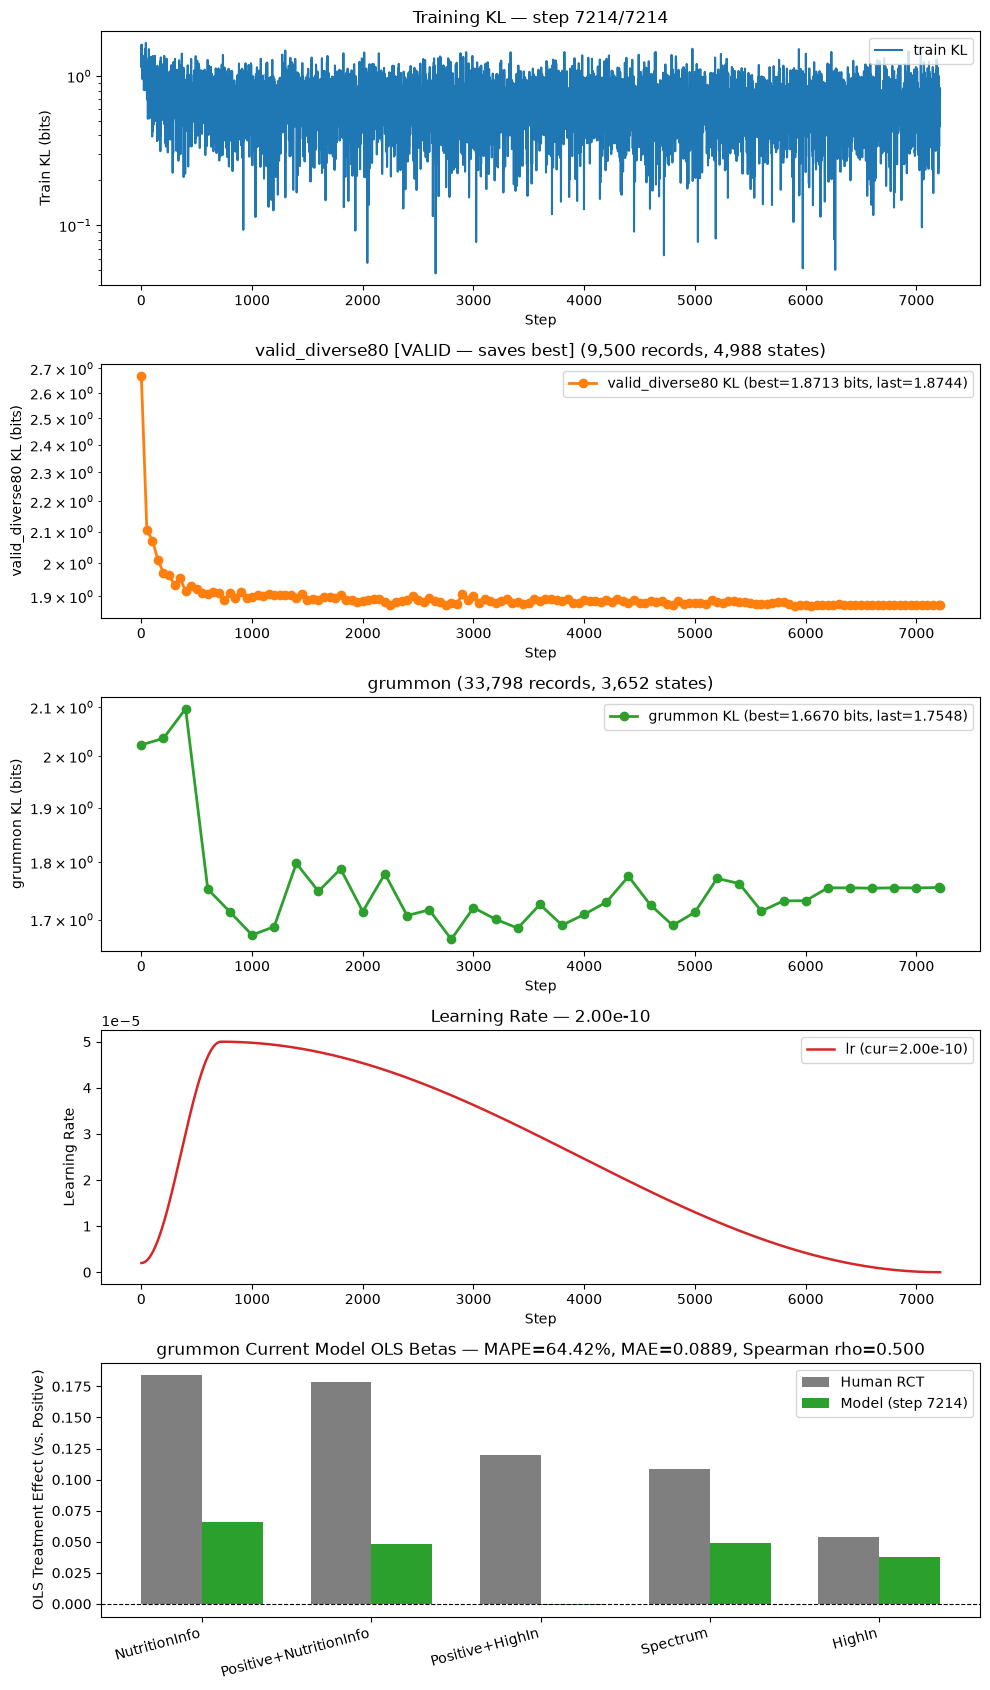

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.6695,2.0224,104.13,0.1164,0.0149,-0.9000
1,1,50,0.8902,2.1052,—,—,—,—,—
2,1,100,0.4228,2.0706,—,—,—,—,—
3,1,150,0.7560,2.0107,—,—,—,—,—
4,1,200,0.8546,1.9694,2.0357,74.46,0.0980,0.0116,-0.5000
5,1,250,0.9943,1.9635,—,—,—,—,—
6,1,300,0.8084,1.9333,—,—,—,—,—
7,1,350,0.9205,1.9550,—,—,—,—,—
8,1,400,0.5794,1.9147,2.0964,65.36,0.0894,0.0097,-0.1000
9,1,450,1.3019,1.9321,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.0661,0.1183
Positive+NutritionInfo,0.1788,0.0483,0.1305
Positive+HighIn,0.1194,-0.0010,0.1205
Spectrum,0.1083,0.0493,0.0590
HighIn,0.0541,0.0381,0.0160


In [16]:
plotter = trainer.train()

## Train one-epoch 2

In [ ]:
resume = False
val_every = [50, 500]
save_every = 50
epochs = 1
lr = 5e-4
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"
seed = 1
warmup_steps = 2000

if PRESET == "9b":
    trainer_cfg = dict(
        init_from="runs/kev-9b-resp-issp+twin2k+wvs-diversevalid-marginals/best",
        save_dir="runs/kev-9b-resp-issp+twin2k+wvs-diversevalid-marginals-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        init_from="runs/kev-0.8b-resp-issp+twin2k+wvs-diversevalid-marginals/best",
        save_dir="runs/kev-0.8b-resp-issp+twin2k+wvs-diversevalid-marginals-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=warmup_steps,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    seed=seed,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

In [ ]:
plotter = trainer.train()

## Train 2 epochs

In [17]:
resume = False
val_every = [50, 200]
save_every = 50
epochs = 2
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k+wvs-diversevalid-marginals-2epochs",
        weights_dtype="bf16",
        use_bf16=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k+wvs-diversevalid-marginals-2epochs",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,MarginalGroupedTrainer
k_schedule,"(1, 2, 3, 4, 5, full, full)"
unique_personas,18924
trait_value_masks,202
run_name,kev-0.8b-resp-issp+twin2k+wvs-diversevalid-mar...
save_dir,runs/kev-0.8b-resp-issp+twin2k+wvs-diversevali...
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64


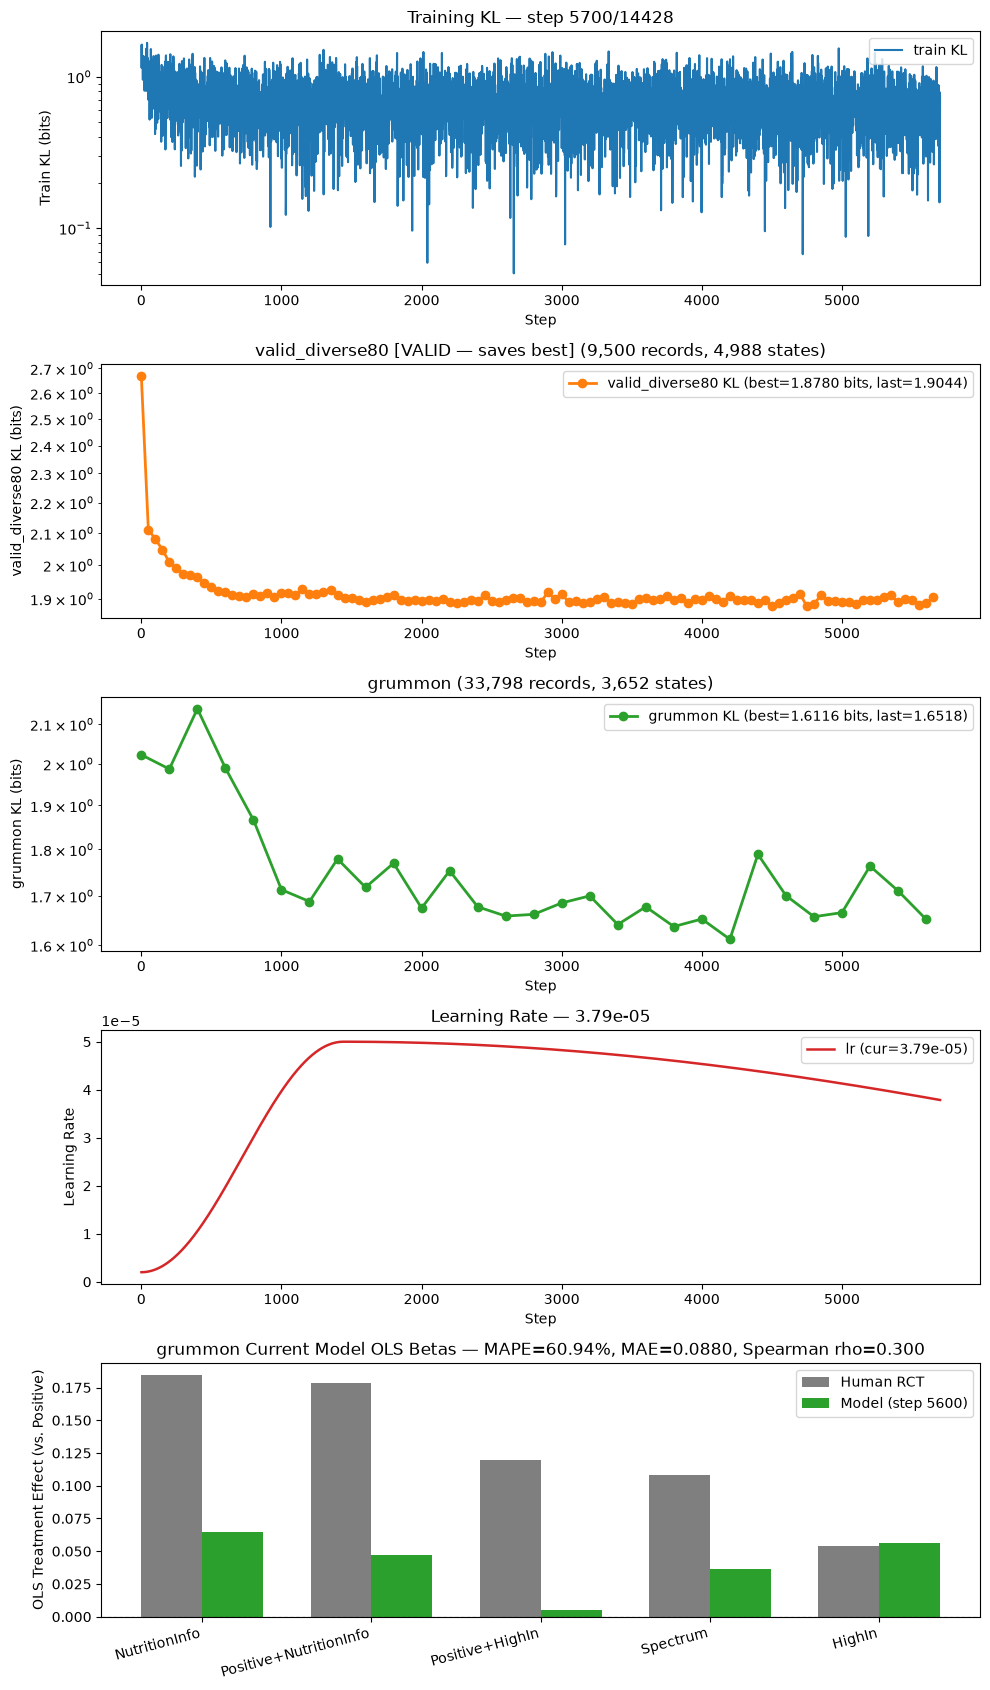

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.6695,2.0224,104.13,0.1164,0.0149,-0.9000
1,1,50,0.8947,2.1113,—,—,—,—,—
2,1,100,0.4479,2.0811,—,—,—,—,—
3,1,150,0.7485,2.0478,—,—,—,—,—
4,1,200,0.8919,2.0086,1.9872,76.92,0.1034,0.0133,-0.9000
5,1,250,0.9828,1.9902,—,—,—,—,—
6,1,300,0.8277,1.9742,—,—,—,—,—
7,1,350,0.9412,1.9703,—,—,—,—,—
8,1,400,0.5571,1.9633,2.1402,79.23,0.1019,0.0119,-0.1000
9,1,450,1.3284,1.9456,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.0646,0.1198
Positive+NutritionInfo,0.1788,0.0474,0.1314
Positive+HighIn,0.1194,0.0048,0.1147
Spectrum,0.1083,0.0360,0.0723
HighIn,0.0541,0.0560,0.0019


In [ ]:
plotter = trainer.train()

## Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [ ]:
df_probe = trainer.probe_vram([
    (32, 16_000),
    (32, 20_000),
    (32, 24_000),
    (64, 24_000),
    (96, 36_000),
    (128, 48_000),
    (160, 60_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)